# Give Me Some Credit — Feature Distribution Analysis

## 1. Objective

The purpose of this notebook is to explore the **Give Me Some Credit** dataset and identify which features show the most meaningful patterns related to credit default.

I first compare six candidate features using differences between Default and No Default customers, median values, Spearman correlation, and default rates across different groups. Based on these comparisons and their credit-risk interpretation, I select three features for a more detailed analysis: `NumberOfTimes90DaysLate`, `RevolvingUtilizationOfUnsecuredLines`, and `age`.

For these three features, I examine their distributions, missing and zero values, possible outliers, and differences between customers who defaulted and those who did not. I also use numerical evidence to support the main observations and explain what the patterns may mean from a credit-risk perspective.

`NumberOfDefault` is not used in the analysis because it is directly related to the target and could lead to data leakage. The original dataset is kept unchanged, and the notebook focuses only on exploratory data analysis, without training a machine-learning model.

## 2. Data Loading and Basic Overview

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


DATA_PATH = Path("GiveMeSomeCredit.csv")
original_data = pd.read_csv(DATA_PATH)
df = original_data.copy(deep=True)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (149724, 14)


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1


In [2]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))

target = "SeriousDlqin"

print("\nTarget variable:", target)
print("Target values:", sorted(df[target].dropna().unique().tolist()))
print("\nTarget counts:")
display(df[target].value_counts().sort_index().rename_axis(target).to_frame("Count"))

Data types:


,dtype
SeriousDlqin,int64
RevolvingUtilizationOfUnsecuredLines,float64
age,int64
SEX,object
EDUCATION,int64
NumberOfTime30-59DaysPastDueNotWorse,int64
DebtRatio,float64
MonthlyIncome,float64
NumberOfOpenCreditLinesAndLoans,int64
NumberOfTimes90DaysLate,int64



Target variable: SeriousDlqin
Target values: [0, 1]

Target counts:


,Count
SeriousDlqin,
0,139845
1,9879


## 3. Candidate Feature Screening

Before deciding on the final three features, I first looked at six possible candidates:

- `NumberOfTimes90DaysLate`
- `RevolvingUtilizationOfUnsecuredLines`
- `NumberOfOpenCreditLinesAndLoans`
- `age`
- `DebtRatio`
- `MonthlyIncome`

I chose these features because they describe different parts of a customer's financial and credit situation. For example, `MonthlyIncome` can give an idea of a customer's ability to manage and repay debt, while delinquency and credit utilization give more direct information about repayment behavior and use of available credit.

To compare the six features, I looked at the differences between Default and No Default customers, compared their median values, checked Spearman correlation with the target, and examined how default rates changed across different groups of each feature.

I did not choose the final features based on only one number. I also considered how clear and consistent the pattern was, whether the feature had a meaningful connection to credit risk, how easy the result was to interpret, and whether there were any important data-quality issues.

In [3]:
candidate_features = [
    "NumberOfTimes90DaysLate",
    "RevolvingUtilizationOfUnsecuredLines",
    "NumberOfOpenCreditLinesAndLoans",
    "age",
    "DebtRatio",
    "MonthlyIncome"
]

group_rows = []

for feature in candidate_features:
    for y, label in [(0, "No Default"), (1, "Default")]:
        s = df.loc[df[target] == y, feature]

        group_rows.append({
            "Feature": feature,
            "Group": label,
            "Mean": s.mean(),
            "Median": s.median()
        })

group_comparison = pd.DataFrame(group_rows)
display(group_comparison.round(3))


,Feature,Group,Mean,Median
0,NumberOfTimes90DaysLate,No Default,0.050,0.000
1,NumberOfTimes90DaysLate,Default,0.665,0.000
2,RevolvingUtilizationOfUnsecuredLines,No Default,5.811,0.133
3,RevolvingUtilizationOfUnsecuredLines,Default,4.417,0.830
4,NumberOfOpenCreditLinesAndLoans,No Default,8.501,8.000
5,NumberOfOpenCreditLinesAndLoans,Default,7.999,7.000
6,age,No Default,52.771,52.000
7,age,Default,46.056,46.000
8,DebtRatio,No Default,350.592,0.363
9,DebtRatio,Default,299.381,0.432


In [4]:
feature_bins = {}

feature_bins["NumberOfTimes90DaysLate"] = pd.cut(
    df["NumberOfTimes90DaysLate"],
    bins=[-0.1, 0, 1, 2, np.inf],
    labels=["0", "1", "2", "3+"]
)

feature_bins["RevolvingUtilizationOfUnsecuredLines"] = pd.cut(
    df["RevolvingUtilizationOfUnsecuredLines"],
    bins=[-np.inf, 0, 0.25, 0.5, 0.75, 1, np.inf],
    labels=["0", "(0, 0.25]", "(0.25, 0.5]",
            "(0.5, 0.75]", "(0.75, 1]", ">1"]
)

feature_bins["NumberOfOpenCreditLinesAndLoans"] = pd.cut(
    df["NumberOfOpenCreditLinesAndLoans"],
    bins=[-0.1, 0, 4, 9, 14, np.inf],
    labels=["0", "1-4", "5-9", "10-14", "15+"]
)

feature_bins["age"] = pd.cut(
    df["age"],
    bins=[-np.inf, 29, 39, 49, 59, 69, np.inf],
    labels=["<30", "30-39", "40-49", "50-59", "60-69", "70+"]
)

feature_bins["DebtRatio"] = pd.qcut(
    df["DebtRatio"],
    q=5,
    duplicates="drop"
)

feature_bins["MonthlyIncome"] = pd.qcut(
    df["MonthlyIncome"],
    q=5,
    duplicates="drop"
)

screen_rows = []

for feature in candidate_features:
    rates = df.groupby(
        feature_bins[feature],
        observed=False
    )[target].mean() * 100

    no_default = df.loc[df[target] == 0, feature]
    default = df.loc[df[target] == 1, feature]

    screen_rows.append({
        "Feature": feature,
        "Median_NoDefault": no_default.median(),
        "Median_Default": default.median(),
        "Spearman_Correlation": df[feature].corr(df[target], method="spearman"),
        "Lowest_Default_Rate_%": rates.min(),
        "Highest_Default_Rate_%": rates.max(),
        "Default_Rate_Spread": rates.max() - rates.min()
    })

screening = pd.DataFrame(screen_rows).sort_values(
    "Default_Rate_Spread",
    ascending=False
)

display(screening.round(3))


,Feature,Median_NoDefault,Median_Default,Spearman_Correlation,Lowest_Default_Rate_%,Highest_Default_Rate_%,Default_Rate_Spread
0,NumberOfTimes90DaysLate,0.000,0.000,0.335,4.627,61.684,57.057
1,RevolvingUtilizationOfUnsecuredLines,0.133,0.830,0.237,2.023,37.259,35.236
2,NumberOfOpenCreditLinesAndLoans,8.000,7.000,-0.033,5.635,20.851,15.216
3,age,52.000,46.000,-0.115,2.313,11.212,8.899
4,DebtRatio,0.363,0.432,0.025,5.459,9.896,4.437
5,MonthlyIncome,5470.000,4500.000,-0.064,4.505,8.873,4.367


### Why the final three features were selected

`NumberOfTimes90DaysLate` was selected because it shows the strongest and clearest increase in default risk as serious delinquency becomes more frequent. `RevolvingUtilizationOfUnsecuredLines` was also selected because it shows a strong default-rate pattern and has a direct credit-risk interpretation related to heavy use of available credit.

`NumberOfOpenCreditLinesAndLoans` shows some separation in default rates, but its pattern is less consistent and less straightforward to interpret than the selected features. `age` was selected instead because its default-rate pattern is clearer and more consistent, and it adds a different type of information from delinquency and utilization.

`MonthlyIncome` was included as a candidate because income is relevant to repayment capacity. However, it was not selected because about **19.77%** of its values are missing and its observed relationship with default is weaker than the three selected features. `DebtRatio` was also not selected because it contains extreme values and its default-rate pattern is less clear.

Therefore, the final three features are:

- `NumberOfTimes90DaysLate`
- `RevolvingUtilizationOfUnsecuredLines`
- `age`


## 4. Summary Statistics for the Selected Features

In [5]:
selected_features = [
    "RevolvingUtilizationOfUnsecuredLines",
    "NumberOfTimes90DaysLate",
    "age"
]

rows = []

for col in selected_features:
    s = df[col]
    nonmissing = s.dropna()

    q1 = nonmissing.quantile(0.25)
    q3 = nonmissing.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((nonmissing < lower) | (nonmissing > upper)).sum()

    rows.append({
        "Feature": col,
        "Missing_n": s.isna().sum(),
        "Missing_%": s.isna().mean() * 100,
        "Zero_n": (s == 0).sum(),
        "Zero_%": (s == 0).mean() * 100,
        "Mean": nonmissing.mean(),
        "Median": nonmissing.median(),
        "Std": nonmissing.std(),
        "Min": nonmissing.min(),
        "25%": q1,
        "75%": q3,
        "Max": nonmissing.max(),
        "Skewness": nonmissing.skew(),
        "IQR_Outliers": outliers
    })

quality = pd.DataFrame(rows).set_index("Feature")
display(quality.round(4))

,Missing_n,Missing_%,Zero_n,Zero_%,Mean,Median,Std,Min,25%,75%,Max,Skewness,IQR_Outliers
Feature,,,,,,,,,,,,,
RevolvingUtilizationOfUnsecuredLines,0,0.0,10877,7.2647,5.7191,0.1535,212.8919,0.0,0.0298,0.5556,29110.0,67.7097,768
NumberOfTimes90DaysLate,0,0.0,141656,94.6114,0.0904,0.0000,0.4855,0.0,0.0000,0.0000,17.0,9.3354,8068
age,0,0.0,1,0.0007,52.3275,52.0000,14.7552,0.0,41.0000,63.0000,109.0,0.1906,46


The table above gives the main descriptive statistics required for the three selected features.  
Potential outliers are identified using the IQR rule, but they are **not removed** from the dataset.

## 5. Feature 1 — RevolvingUtilizationOfUnsecuredLines

,count,mean,median,std
SeriousDlqin,,,,
No Default,139845,5.8111,0.1330,217.4365
Default,9879,4.4174,0.8301,132.8125


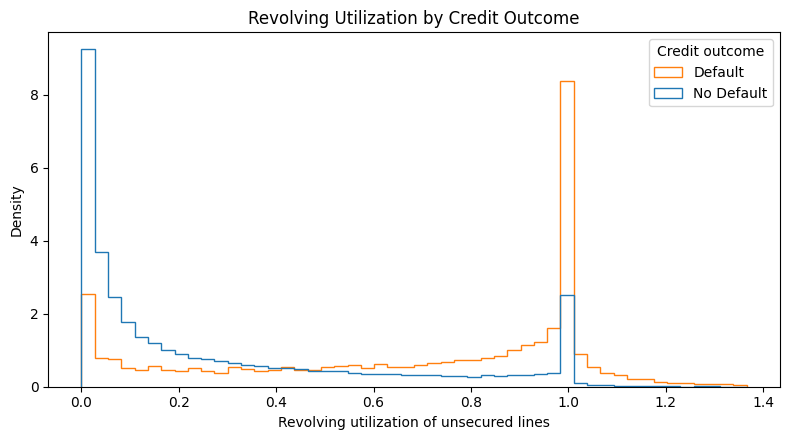

,Default rate (%)
RevolvingUtilizationOfUnsecuredLines,
0,2.94
"(0, 0.25]",2.02
"(0.25, 0.5]",5.29
"(0.5, 0.75]",10.13
"(0.75, 1]",17.80
>1,37.26


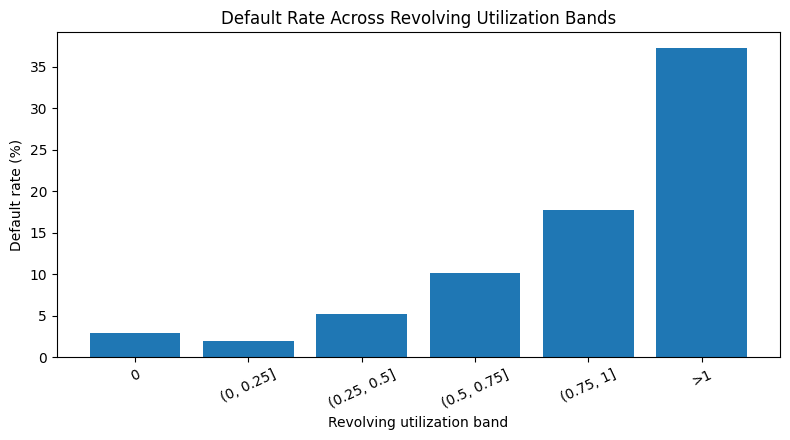

In [6]:
feature = "RevolvingUtilizationOfUnsecuredLines"

group_summary = df.groupby(target)[feature].agg(
    ["count", "mean", "median", "std"]
).rename(index={0: "No Default", 1: "Default"})

display(group_summary.round(4))


p995 = df[feature].quantile(0.995)
viz = df[df[feature] <= p995].copy()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(
    [
        viz.loc[viz[target] == 0, feature],
        viz.loc[viz[target] == 1, feature]
    ],
    bins=50,
    density=True,
    histtype="step",
    label=["No Default", "Default"]
)
ax.set_title("Revolving Utilization by Credit Outcome")
ax.set_xlabel("Revolving utilization of unsecured lines")
ax.set_ylabel("Density")
ax.legend(title="Credit outcome")
plt.tight_layout()
plt.show()

util_band = pd.cut(
    df[feature],
    bins=[-np.inf, 0, 0.25, 0.5, 0.75, 1, np.inf],
    labels=["0", "(0, 0.25]", "(0.25, 0.5]", "(0.5, 0.75]", "(0.75, 1]", ">1"]
)

util_rate = df.groupby(util_band, observed=False)[target].mean() * 100
display(util_rate.to_frame("Default rate (%)").round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(util_rate.index.astype(str), util_rate.values)
ax.set_title("Default Rate Across Revolving Utilization Bands")
ax.set_xlabel("Revolving utilization band")
ax.set_ylabel("Default rate (%)")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

### Interpretation

**Observed in the data:** `RevolvingUtilizationOfUnsecuredLines` is extremely positively skewed (skewness **67.71**) and has no missing values. The median is **0.153**, while the maximum is **29,110**, showing a very long right tail. The Default group has a median utilization of **0.830**, compared with **0.133** for the No Default group.

The default rate rises from **2.02%** for utilization between 0 and 0.25 to **17.80%** for utilization between 0.75 and 1, and **37.26%** for values above 1. The histogram is restricted to the 99.5th percentile **only for visualization**; the original data is not changed.

**Possible credit-risk interpretation:** higher revolving utilization may indicate greater use of available credit and less remaining borrowing capacity, which can be associated with financial stress. Extremely large values should be interpreted cautiously because they may also reflect unusual or problematic observations.

## 6. Feature 2 — NumberOfTimes90DaysLate

,count,mean,median,std
SeriousDlqin,,,,
No Default,139845,0.0499,0.0,0.3326
Default,9879,0.6650,0.0,1.2858


SeriousDlqin,No Default,Default
NumberOfTimes90DaysLate,,
0,96.61,66.34
1,2.49,17.87
2,0.56,7.86
3+,0.35,7.94


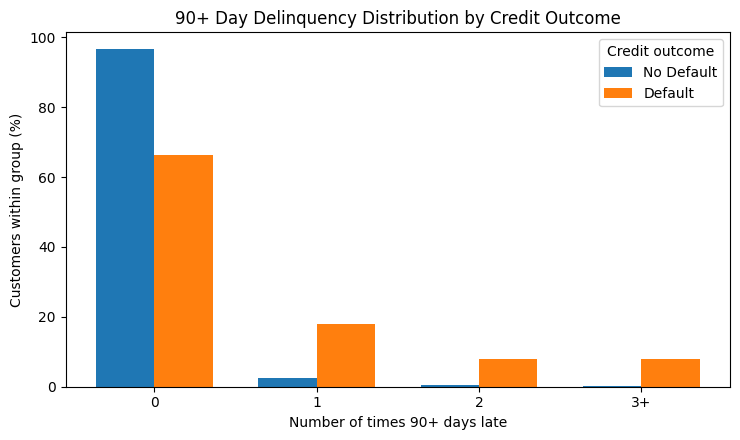

,Default rate (%)
NumberOfTimes90DaysLate,
0,4.63
1,33.66
2,49.94
3+,61.68


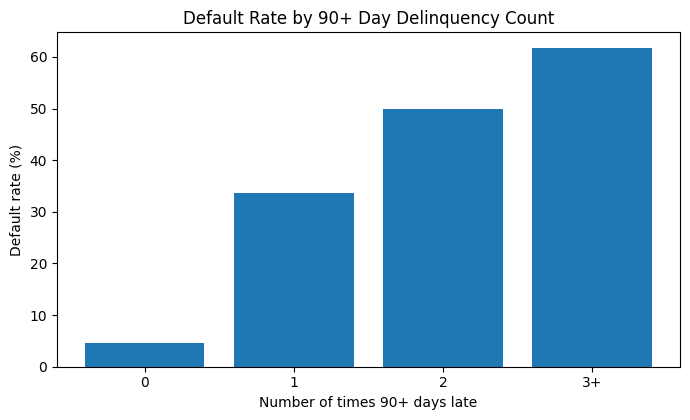

In [7]:
feature = "NumberOfTimes90DaysLate"

group_summary = df.groupby(target)[feature].agg(
    ["count", "mean", "median", "std"]
).rename(index={0: "No Default", 1: "Default"})

display(group_summary.round(4))

late_bucket = pd.cut(
    df[feature],
    bins=[-0.1, 0, 1, 2, np.inf],
    labels=["0", "1", "2", "3+"]
)

late_distribution = pd.crosstab(
    late_bucket,
    df[target],
    normalize="columns"
).mul(100).rename(columns={0: "No Default", 1: "Default"})

display(late_distribution.round(2))

x = np.arange(len(late_distribution.index))
width = 0.36

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(x - width/2, late_distribution["No Default"], width, label="No Default")
ax.bar(x + width/2, late_distribution["Default"], width, label="Default")
ax.set_title("90+ Day Delinquency Distribution by Credit Outcome")
ax.set_xlabel("Number of times 90+ days late")
ax.set_ylabel("Customers within group (%)")
ax.set_xticks(x, late_distribution.index.astype(str))
ax.legend(title="Credit outcome")
plt.tight_layout()
plt.show()

late_rate = df.groupby(late_bucket, observed=False)[target].mean() * 100
display(late_rate.to_frame("Default rate (%)").round(2))

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.bar(late_rate.index.astype(str), late_rate.values)
ax.set_title("Default Rate by 90+ Day Delinquency Count")
ax.set_xlabel("Number of times 90+ days late")
ax.set_ylabel("Default rate (%)")
plt.tight_layout()
plt.show()

### Interpretation

**Observed in the data:** `NumberOfTimes90DaysLate` is strongly positively skewed (skewness **9.34**) and has a large number of zeros: **94.61%** of customers have no 90+ day delinquency. The mean is **0.665** for Default customers and **0.050** for No Default customers.

The default rate increases from **4.63%** for customers with no 90+ day delinquency to **33.66%** for one delinquency, **49.94%** for two, and **61.68%** for three or more.

**Possible credit-risk interpretation:** repeated 90+ day late payments are direct evidence of serious repayment difficulty, so the strong association with default is economically plausible. These nonzero values should not be automatically removed as outliers because they represent meaningful repayment behavior.

## 7. Feature 3 — age

,count,mean,median,std
SeriousDlqin,,,,
No Default,139845,52.7705,52.0,14.7796
Default,9879,46.0562,46.0,12.8616


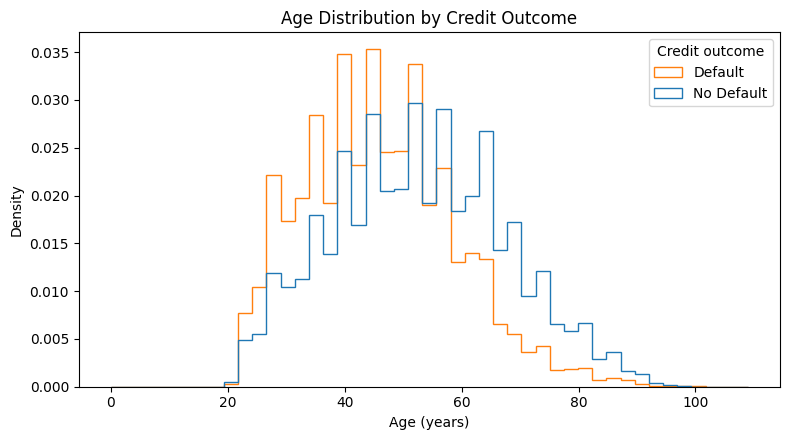

,Default rate (%)
age,
<30,11.21
30-39,9.97
40-49,8.31
50-59,6.39
60-69,3.60
70+,2.31


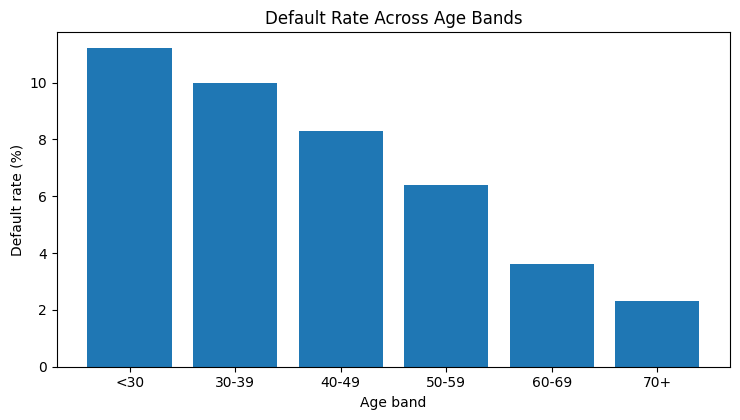

In [8]:
feature = "age"

group_summary = df.groupby(target)[feature].agg(
    ["count", "mean", "median", "std"]
).rename(index={0: "No Default", 1: "Default"})

display(group_summary.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(
    [
        df.loc[df[target] == 0, feature],
        df.loc[df[target] == 1, feature]
    ],
    bins=45,
    density=True,
    histtype="step",
    label=["No Default", "Default"]
)
ax.set_title("Age Distribution by Credit Outcome")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Density")
ax.legend(title="Credit outcome")
plt.tight_layout()
plt.show()

age_band = pd.cut(
    df[feature],
    bins=[-np.inf, 29, 39, 49, 59, 69, np.inf],
    labels=["<30", "30-39", "40-49", "50-59", "60-69", "70+"]
)

age_rate = df.groupby(age_band, observed=False)[target].mean() * 100
display(age_rate.to_frame("Default rate (%)").round(2))

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.bar(age_rate.index.astype(str), age_rate.values)
ax.set_title("Default Rate Across Age Bands")
ax.set_xlabel("Age band")
ax.set_ylabel("Default rate (%)")
plt.tight_layout()
plt.show()

### Interpretation

**Observed in the data:** `age` has no missing values and is only slightly positively skewed (skewness **0.19**). The Default group has a median age of **46**, compared with **52** for the No Default group. The dataset contains one age value of 0, which is likely a data-quality issue.

The default rate decreases from **11.21%** for customers under 30 to **2.31%** for customers aged 70 or above.

**Possible credit-risk interpretation:** younger customers may have shorter credit histories or less financial stability on average, but this is only a possible explanation. The observed relationship is an association and should not be interpreted as proof that age causes default.

## 8. Final Insights

If I could select only three features as a starting point for credit risk analysis, I would choose `NumberOfTimes90DaysLate`, `RevolvingUtilizationOfUnsecuredLines`, and `age`. The data show strong and interpretable differences in severe delinquency and credit utilization between Default and No Default customers, while age provides an additional and distinct pattern associated with credit risk.